# Relaxation pathways

Which operators does relaxation connect, through which mechanism, and how
fast? `spynach.relaxation_pathways` answers this for a spin system defined
as in the other guides. It builds the Bloch-Redfield-Wangsness (BRW)
relaxation matrix between product operators and splits every element into
the contributions of the relaxation mechanisms (dipole-dipole `DD`,
shielding anisotropy `CSA`, quadrupolar `Q`, anisotropic scalar coupling
`JA`) and of every cross-correlation between two of them (`DD/CSA`,
`DD/DD`, `CSA/Q`, ...). Each contribution comes both as a rate and as an
exact expression in the interaction strengths and the spectral density.
`spynach.plotting.plot_pathways` draws the result as a chord diagram, with
one colour per mechanism and ribbons as wide as the rates. The feature has
no Spinach counterpart; its rates are checked against
`spynach.relaxation`. Read the [relaxation guide](relaxation.ipynb) first. The
guide [TROSY of a rotating ¹³CF₃ group](cf3-trosy.ipynb) applies it to internal
rotation (axially symmetric diffusion) and to the ¹³C single-quantum block of
a ¹³CF₃ group, classes resolved by interaction, and
[Relaxation at zero and ultralow field](zulf-pathways.ipynb) to the populations
of the J-coupled energy levels after an adiabatic transfer, and to the widths
of the lines. The
companion notebook is
[`notebooks/relaxation-pathways.ipynb`](relaxation-pathways.ipynb)
([interactive figures on nbviewer](https://nbviewer.org/github/ajerschow/spynach/blob/main/docs/notebooks/relaxation-pathways.ipynb)).

Every Python block is executed by `tests/docs/`, in order and in one
namespace. The expressions need SymPy (`pip install -e ".[symbolic]"`).

*Generated from [`docs/relaxation-pathways.md`](../relaxation-pathways.md) by `docs/build_notebooks.py`; edit the Markdown guide, not this notebook.*

Run the cells in order: later cells use names defined by earlier ones. The saved outputs come from running the notebook top to bottom; plotting cells need Plotly (`pip install -e ".[docs]"`).

## Contents

1. [The method](#The-method)
2. [Tetrafluoroborate](#Tetrafluoroborate)
3. [Mechanisms and symbols](#Mechanisms-and-symbols)
4. [Rates and expressions](#Rates-and-expressions)
5. [The chord diagram](#The-chord-diagram)
6. [The zero-quantum space and the boron quadrupole](#The-zero-quantum-space-and-the-boron-quadrupole)
7. [Secular approximations](#Secular-approximations)
8. [Cross-correlations that cancel by symmetry](#Cross-correlations-that-cancel-by-symmetry)
9. [Checking against the Redfield superoperator](#Checking-against-the-Redfield-superoperator)
10. [Options and limits](#Options-and-limits)

## The method

Each mechanism `mu` is a rank-2 interaction with a spatial tensor fixed in
the molecule and spin tensor operators `T^mu_q`. Under isotropic rotational
diffusion with correlation time `tau_c`, the correlation function of two
mechanisms is `(G_mu_nu / 5) exp(-t / tau_c)`, where `G_mu_nu` is the scalar
product of their rank-2 tensors. It carries the geometry exactly, for
instance `P2(cos theta)` for two axial tensors at an angle `theta`. The BRW
master equation is `d<O_i>/dt = -sum_j Gamma[i, j] <O_j>` with

    Gamma = sum_{mu,nu} sum_q sum_w (G_mu_nu / 5) J(w) [T^mu_{q,w}, [T^nu_{q,w}^+, . ]]
    J(w) = tau_c / (1 + w^2 tau_c^2)

where `T_{q,w}` is the part of `T_q` that oscillates at the frequency `w`
of the Zeeman Hamiltonian, and the dynamic frequency shifts are dropped
(as with `rlx_dfs = "ignore"`). The diagonal elements are auto-relaxation
rates, the off-diagonal ones cross-relaxation rates. The terms with
`mu = nu` make the auto-correlated classes (`DD`, `CSA`, `Q`, `JA`), the
others the cross-correlated classes, named after the two kinds.

Strengths are kept as symbols. The double commutators are evaluated
numerically in Hilbert space between normalised product operators, and the
remaining numbers, which come from geometry and spin algebra, are
recognised as rationals or square roots of rationals. Each matrix element
then becomes an exact expression, for example `b_BF**2 * (6*J(omega_B +
omega_F) - J(omega_B - omega_F)) * sqrt(5)/5`.

## Tetrafluoroborate

In ¹¹BF₄⁻ the boron (I = 3/2) sits at the centre of a tetrahedron of four
fluorines (I = 1/2). The relaxation mechanisms are:

- the ¹¹B–¹⁹F and ¹⁹F–¹⁹F dipolar couplings;
- the ¹⁹F shielding anisotropy, axial along each B–F bond by site symmetry;
- the ¹¹B quadrupole and shielding anisotropy.

The boron tensors vanish in a perfect tetrahedron and become nonzero when
the anion is distorted or paired with a cation. Here they are given along
the first B–F bond, a C3v distortion, so that the example has every
mechanism. The numbers are illustrative; replace them with measured or
computed values for a real sample.

| parameter | value here |
|---|---|
| B0 | 9.4 T |
| r(B–F) | 1.40 Å |
| Δσ(¹⁹F) = σ∥ − σ⊥ | 100 ppm, along each B–F bond |
| Δσ(¹¹B) | 2 ppm, along the first B–F bond |
| C_Q(¹¹B) = e²qQ/h | 100 kHz, η = 0, along the first B–F bond |
| τ_c | 10 ps |

In [1]:
import numpy as np

import spynach
from spynach.conventions import eeqq2nqi
from spynach.plotting import plot_pathways


def tetrafluoroborate(magnet=9.4, r_bf=1.40, dsigma_f=100.0, dsigma_b=2.0, cq_b=0.1e6, tau_c=10e-12, keep="secular"):
    """11BF4-: boron at the origin, the first B-F bond along z."""
    corners = np.array([[1, 1, 1], [1, -1, -1], [-1, 1, -1], [-1, -1, 1]]) / np.sqrt(3)
    z = corners[0]
    x = np.cross(z, [0, 0, 1.0])
    x /= np.linalg.norm(x)
    bonds = corners @ np.array([x, np.cross(z, x), z]).T  # unit vectors from B to each F

    def axial(n, anisotropy):  # shielding tensor in ppm with sigma_par - sigma_perp = anisotropy along n
        return (anisotropy * (np.outer(n, n) - np.eye(3) / 3)).tolist()

    quadrupole = eeqq2nqi(cq_b, 0.0, 1.5, [0, 0, 0]).tolist()
    return spynach.create(
        {"isotopes": ["11B", "19F", "19F", "19F", "19F"], "magnet": magnet},
        {
            "zeeman": {"matrix": [axial([0, 0, 1], dsigma_b)] + [axial(n, dsigma_f) for n in bonds]},
            "coupling": {"matrix": [[quadrupole] + [None] * 4] + [[None] * 5 for _ in range(4)]},
            "coordinates": [[0, 0, 0]] + (r_bf * bonds).tolist(),
            "relaxation": ["redfield"],
            "rlx_keep": keep,
            "equilibrium": "zero",
            "tau_c": [[tau_c]],
        },
    )


bf4 = tetrafluoroborate()
pathways = spynach.relaxation_pathways(bf4)

`relaxation_pathways` reads the mechanisms from the interactions of the
spin system and needs no basis. By default the four fluorines form one
group of equivalent spins (same isotope, same isotropic shift), and the
basis holds the collective operators: `Fz` is `sum_k F_kz`, `BzF+` is
`Bz sum_k F_k+`, each normalised. With the default `max_order=2` and
rank-1 operators, there are 15 basis operators, every product of `E`,
`Bz`, `B+`, `B-` with `E`, `Fz`, `F+`, `F-` except the unit operator.

## Mechanisms and symbols

In [2]:
print([mechanism.name for mechanism in pathways.mechanisms])
print({str(symbol): f"{value:.4g}" for symbol, value in pathways.symbols.items()})
print(pathways.labels)
print(pathways.classes)

['CSA(B)', 'Q(B)', 'CSA(F1)', 'CSA(F2)', 'CSA(F3)', 'CSA(F4)', 'DD(B,F1)', 'DD(B,F2)', 'DD(B,F3)', 'DD(B,F4)', 'DD(F1,F2)', 'DD(F1,F3)', 'DD(F1,F4)', 'DD(F2,F3)', 'DD(F2,F4)', 'DD(F3,F4)']
{'omega_B': '8.07e+08', 'omega_F': '2.367e+09', 'dsigma_B': '2e-06', 'CQ_B': '1e+05', 'dsigma_F': '0.0001', 'b_BF': '8.308e+04', 'b_FF': '5.596e+04'}
['Bz', 'Fz', 'BzFz', 'B+F-', 'B-F+', 'F+', 'BzF+', 'B+', 'B+Fz', 'B+F+', 'B-F-', 'F-', 'BzF-', 'B-', 'B-Fz']
['DD', 'CSA', 'Q', 'DD/DD', 'DD/CSA']


There are sixteen mechanisms: `CSA(B)`, `Q(B)`, four `CSA(Fk)`, four
`DD(B,Fk)` and six `DD(Fk,Fl)`. Interactions of equal strength share a
symbol, and the strength of each kind is, in rad/s:

| kind | strength | symbols |
|---|---|---|
| `DD` | `b_XY = mu0 gamma_X gamma_Y hbar / (4 pi r^3)` | `b_BF`, `b_FF` |
| `CSA` | `omega_X * dsigma_X`, with `omega_X = abs(gamma_X B0)` and `dsigma_X = sigma_par - sigma_perp` (3/2 of the Haeberlen anisotropy) | `dsigma_B`, `dsigma_F` |
| `Q` | `2 pi CQ_X`, with `CQ_X = e^2 q Q / h` in Hz | `CQ_B` |
| `JA` | `2 pi dJ_XY`, with `dJ_XY = J_par - J_perp` in Hz | — |

The orientation of each tensor enters only the numerical factors. An
asymmetric tensor is allowed; its asymmetry then appears in the numbers,
which may stay floating-point.

## Rates and expressions

`pathways.links()` lists the nonzero off-diagonal elements, largest first,
with the rate and the expression of each contributing class.
`pathways.table()` writes them as a Markdown table (LaTeX by default, or
SymPy's text form). `pathways.expression(a, b, classes)` and
`pathways.rate_matrix(classes)` give single elements and whole matrices,
from all classes or the ones named:

In [3]:
print(pathways.table(latex=False))
print(pathways.expression("Fz", "Fz"))
gamma = pathways.rate_matrix()
print(f"R1(19F) = {gamma[pathways.index('Fz'), pathways.index('Fz')]:.4f} s^-1")

| pathway | mechanism | rate (s⁻¹) | expression |
|---|---|---:|---|
| F+ <-> BzF+ | DD/CSA | 0.2052 | sqrt(5)*b_BF*dsigma_F*omega_F*(4*J(0) + 3*J(omega_F))/15 |
| F- <-> BzF- | DD/CSA | 0.2052 | sqrt(5)*b_BF*dsigma_F*omega_F*(4*J(0) + 3*J(omega_F))/15 |
| Fz <-> BzFz | DD/CSA | 0.1758 | 2*sqrt(5)*b_BF*dsigma_F*omega_F*J(omega_F)/5 |
| Bz <-> Fz | DD | 0.1542 | sqrt(5)*b_BF**2*(-J(omega_B - omega_F) + 6*J(omega_B + omega_F))/5 |
b_BF**2*(3*J(omega_F)/2 + J(omega_B - omega_F)/2 + 3*J(omega_B + omega_F)) + 9*b_FF**2*(J(omega_F) + 4*J(2*omega_F))/10 + 2*dsigma_F**2*omega_F**2*J(omega_F)/15
R1(19F) = 0.5602 s^-1


In the high-field secular approximation, only four cross-relaxation
pathways exist between these operators:

| pathway | class | expression | rate (s⁻¹) |
|---|---|---|---:|
| $F_\pm \leftrightarrow B_zF_\pm$ | DD/CSA | $\frac{\sqrt5}{15}\, b_{BF}\,\omega_F\Delta\sigma_F\,[4J(0) + 3J(\omega_F)]$ | 0.205 |
| $F_z \leftrightarrow B_zF_z$ | DD/CSA | $\frac{2\sqrt5}{5}\, b_{BF}\,\omega_F\Delta\sigma_F\,J(\omega_F)$ | 0.176 |
| $B_z \leftrightarrow F_z$ | DD | $\frac{\sqrt5}{5}\, b_{BF}^2\,[6J(\omega_B+\omega_F) - J(\omega_B-\omega_F)]$ | 0.154 |

The ¹⁹F longitudinal rate collects three mechanisms:

$$R_1(F) = b_{BF}^2\left[\tfrac32 J(\omega_F) + \tfrac12 J(\omega_B-\omega_F) + 3J(\omega_B+\omega_F)\right] + \tfrac{9}{10}\, b_{FF}^2\left[J(\omega_F) + 4J(2\omega_F)\right] + \tfrac{2}{15}\,\omega_F^2\Delta\sigma_F^2\, J(\omega_F)$$

These are the textbook forms: the dipolar term is Solomon's with the
factor `(4/3) S (S+1) = 5` of a spin-3/2 partner, the homonuclear term is
three fluorine neighbours at `3/10 b^2 [J(w) + 4J(2w)]` each, and the CSA
term is the familiar `2/15`. The ¹¹B longitudinal rate has the quadrupolar
term `2 pi^2/25 CQ^2 [J(w_B) + 4J(2 w_B)]`, which reduces to Abragam's
`(2/5) pi^2 CQ^2 tau_c` in extreme narrowing.

## The chord diagram

`plot_pathways` puts every basis operator on a circle, grouped by total
coherence order (0 on the left, +1 above, -1 below), and draws each
pathway as a ribbon as wide as its rate. The colour of a ribbon names the
classes that contribute to it, so `DD + DD/CSA` marks a pathway driven by
the dipolar coupling and by its cross-correlation with the shielding
anisotropy. Hover over a ribbon for the rates and expressions, or over an
operator for its auto-relaxation rate:

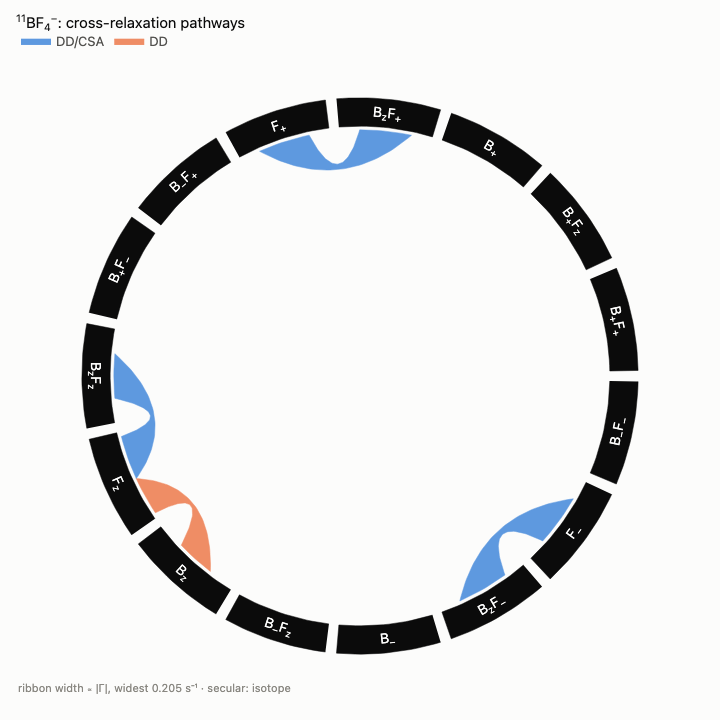

In [4]:
plot_pathways(pathways, title="<sup>11</sup>BF<sub>4</sub><sup>−</sup>: cross-relaxation pathways")

`split=True` draws one ribbon per class side by side, each as wide as that
class's rate. `merge={"DD/DD": "DD"}` counts the dipolar cross-correlations
as dipolar, `classes=[...]` keeps only some classes, and `min_rate` hides
the weak pathways.

The geometry comes from `spynach.plotting.chord_layout`, which returns the
arcs and ribbons as plain lists (outlines, colour indices, hover texts) with
no Plotly. The browser playground draws the same diagram from it as SVG: the
example [`try.html#ex-pathways`](https://ajerschow.github.io/spynach/try.html#ex-pathways)
runs this ¹¹BF₄⁻ analysis in Pyodide, with the field, the B–F distance, the
anisotropies, the quadrupolar coupling, the correlation time, the coherence
order, the boron ranks and the secular approximation in its parameter form,
and `show_pathways(pathways)` draws any analysis written in its editor. To
run the page from a checkout, serve the repository root over HTTP
(`python -m http.server`) and open `http://localhost:8000/try.html#ex-pathways`.

## The zero-quantum space and the boron quadrupole

A spin-3/2 nucleus has rank-2 and rank-3 operators besides `Bz`, `B+` and
`B-`, and the quadrupole couples them to the rank-1 ones. `ranks` adds
them: `B(2,0)` is the quadrupolar order `T(2,0)` of ¹¹B and `B(3,+1)` is
`T(3,+1)`. `coherence=0` keeps the zero-quantum space, the operators of
total coherence order 0:

In [5]:
zq = spynach.relaxation_pathways(bf4, ranks={"B": (1, 2, 3)}, coherence=0)
print(zq.labels)
print(zq.table(latex=False))

['Bz', 'B(2,0)', 'B(3,0)', 'Fz', 'BzFz', 'B(2,0)Fz', 'B(3,0)Fz', 'B+F-', 'B(2,+1)F-', 'B(3,+1)F-', 'B-F+', 'B(2,-1)F+', 'B(3,-1)F+']
| pathway | mechanism | rate (s⁻¹) | expression |
|---|---|---:|---|
| B(3,0) <-> B(2,0)Fz | DD | 0.185 | 6*sqrt(5)*b_BF**2*(-J(omega_B - omega_F) + 6*J(omega_B + omega_F))/25 |
| B(2,0) <-> BzFz | DD | 0.185 | 6*sqrt(5)*b_BF**2*(-J(omega_B - omega_F) + 6*J(omega_B + omega_F))/25 |
| Fz <-> BzFz | DD/CSA | 0.1758 | 2*sqrt(5)*b_BF*dsigma_F*omega_F*J(omega_F)/5 |
| Bz <-> Fz | DD | 0.1542 | sqrt(5)*b_BF**2*(-J(omega_B - omega_F) + 6*J(omega_B + omega_F))/5 |
| B+F- <-> B(2,+1)F- | DD/CSA | -0.1421 | -2*sqrt(15)*b_BF*dsigma_F*omega_F*(4*J(0) + 3*J(omega_F))/75 |
|  | CSA/Q | 0.001571 | 2*sqrt(15)*pi*CQ_B*dsigma_B*omega_B*(2*J(0) + J(omega_B))/75 |
| B-F+ <-> B(2,-1)F+ | DD/CSA | 0.1421 | 2*sqrt(15)*b_BF*dsigma_F*omega_F*(4*J(0) + 3*J(omega_F))/75 |
|  | CSA/Q | -0.001571 | -2*sqrt(15)*pi*CQ_B*dsigma_B*omega_B*(2*J(0) + J(omega_B))/75 |
| BzFz <-> B(2,0)Fz | 

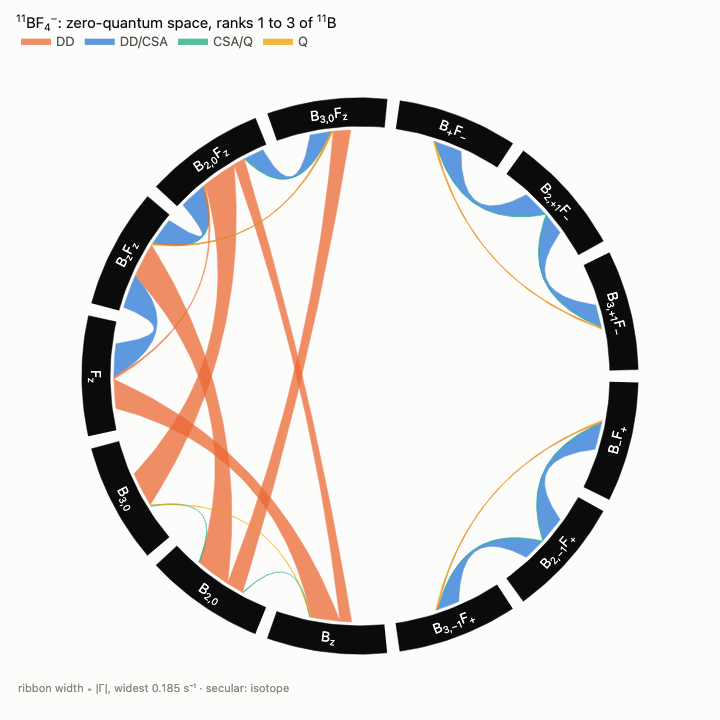

In [6]:
plot_pathways(zq, split=True, title="<sup>11</sup>BF<sub>4</sub><sup>−</sup>: zero-quantum space, ranks 1 to 3 of <sup>11</sup>B")

The longitudinal block ($B_z$, $B_{2,0}$, $B_{3,0}$, $F_z$ and their
products with $F_z$) shows every mechanism at work:

| pathway | class | expression |
|---|---|---|
| $B_z \leftrightarrow B_{3,0}$ | Q | $\frac{4\pi^2}{25}\, C_Q^2\,[J(\omega_B) - J(2\omega_B)]$ |
| $B_z \leftrightarrow B_{2,0}$ | CSA/Q | $-\frac{4\sqrt5}{25}\,\pi C_Q\,\omega_B\Delta\sigma_B\,J(\omega_B)$ |
| $B_{2,0} \leftrightarrow B_zF_z$ | DD | $\frac{6\sqrt5}{25}\, b_{BF}^2\,[6J(\omega_B+\omega_F) - J(\omega_B-\omega_F)]$ |
| $B_zF_z \leftrightarrow B_{2,0}F_z$ | DD/CSA, CSA/Q | $\frac{8\sqrt5}{25}\, b_{BF}\,\omega_F\Delta\sigma_F\,J(\omega_F) - \frac{4\sqrt5}{25}\,\pi C_Q\,\omega_B\Delta\sigma_B\,J(\omega_B)$ |

The quadrupole mixes the rank-1 and rank-3 longitudinal orders of the
boron outside extreme narrowing (the familiar biexponential relaxation of
a spin 3/2). The ¹¹B–¹⁹F dipolar couplings convert heteronuclear
two-spin order into boron quadrupolar order. The cross-correlation of the
boron's own shielding and quadrupole connects `Bz` with `B(2,0)`. The
zero-quantum coherences `B+F-` and `B-F+` form separate blocks: in the
secular approximation an operator only relaxes into operators with the same
coherence order of every isotope.

## Secular approximations

`secular` sets which pairs of frequency components are kept:

| `secular` | keeps | connects |
|---|---|---|
| `"isotope"` (default) | equal frequencies | operators with the same coherence order of every isotope; the usual high-field approximation |
| `"total"` | equal total coherence order | also `B+F-` with `BzFz`, or `B+` with `F+`; these terms oscillate at `w_B - w_F` and are secular only when the Larmor frequencies are close |
| `"none"` | everything | the lab-frame Redfield superoperator (`rlx_keep = "labframe"`) |

The secular forms are masks of the lab-frame matrix: they keep its
elements between operators of equal coherence, per isotope or in total.
Pathway diagrams in the literature are sometimes drawn in the `"total"`
form, which shows many more pathways. For ¹¹B and ¹⁹F, `w_B - w_F` is
2π × 248 MHz at 9.4 T and these extra terms average out:

In [7]:
total = spynach.relaxation_pathways(bf4, secular="total")
print(len(pathways.links()), "pathways with secular='isotope',", len(total.links()), "with secular='total'")

4 pathways with secular='isotope', 19 with secular='total'


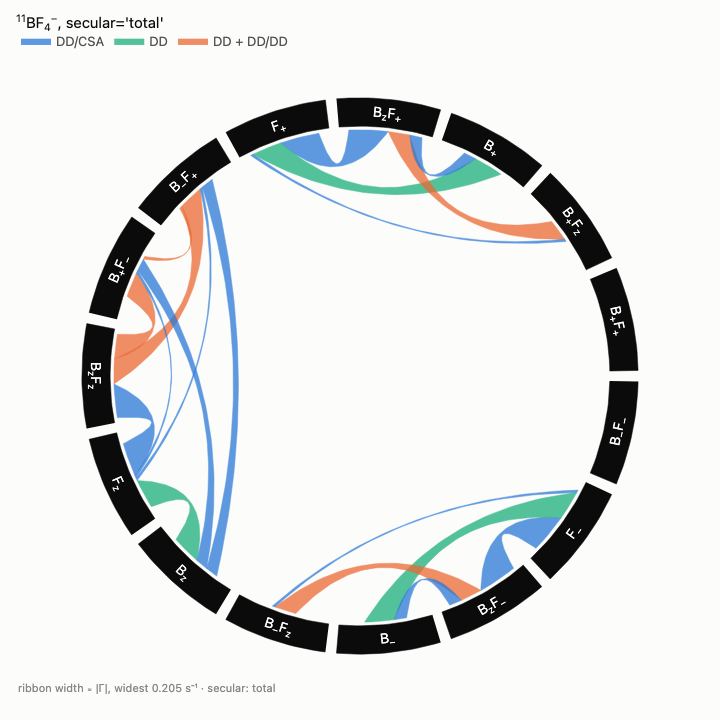

In [8]:
plot_pathways(total, title="<sup>11</sup>BF<sub>4</sub><sup>−</sup>, secular='total'")

## Cross-correlations that cancel by symmetry

In the collective basis there is no `DD/Q` class, even though the boron
quadrupole lies along a B–F bond. The cross-correlation of the quadrupole
with the dipolar coupling to fluorine k is proportional to
`P2(n . r_k)`, and for any axis `n` the four bonds of a tetrahedron give
`sum_k P2(n . r_k) = 0`. An operator that is symmetric in the four
fluorines therefore sees no cross-correlation between a boron tensor and
the B–F dipoles, whatever the boron tensor's orientation. The same holds
for the boron shielding against the fluorine mechanisms. The terms are there
for each B–F pair and show up as soon as the basis tells the fluorines
apart, either with a single B–F pair or with groups that single out the
fluorine on the axis:

In [9]:
pair = spynach.kill_spin(bf4, [2, 3, 4])  # 11B and the fluorine on the boron tensors' axis
pair_zq = spynach.relaxation_pathways(pair, ranks={"B": (1, 2, 3)}, coherence=0)
print(pair_zq.classes)
print(pair_zq.expression("Bz", "B(2,0)Fz", "DD/Q"))

on_axis = spynach.relaxation_pathways(bf4, groups=[[0], [1], [2, 3, 4]], ranks={"B": (1, 2, 3)}, coherence=0)
print(on_axis.labels[:6])
print("DD/Q" in on_axis.classes)

['DD', 'CSA', 'Q', 'DD/CSA', 'DD/Q', 'CSA/CSA', 'CSA/Q']
-6*sqrt(5)*pi*CQ_B*b_BF*J(omega_B)/25
['Bz', 'B(2,0)', 'B(3,0)', 'F1z', 'F234z', 'BzF1z']
True


With the fluorine on the axis in a group of its own (`F1`) and the other
three together (`F234`), the DD/Q pathways appear with opposite signs for
the two groups. They cancel again in the sum `F1 + F234`, the collective
operator of the first analysis.

## Checking against the Redfield superoperator

The same relaxation matrix comes out of `spynach.relaxation`, which
evaluates the Redfield integral numerically (Kuprov's
diagonalisation-free form, see the [relaxation guide](relaxation.ipynb)).
`pathways.states(spin_system)` gives the basis operators as unit vectors of
the `sphten-liouv` basis, so the comparison is one projection. The
lab-frame superoperator is compared with `secular="none"`:

In [10]:
lab = spynach.basis(tetrafluoroborate(keep="labframe"), {"formalism": "sphten-liouv", "approximation": "none"})
full = spynach.relaxation_pathways(lab, secular="none", ranks={"B": (1, 2, 3)})
V = full.states(lab)
gamma_redfield = -(V.conj() @ (spynach.relaxation(lab) @ V.T)).real
difference = np.abs(gamma_redfield - full.rate_matrix()).max() / np.abs(gamma_redfield).max()
print(f"{len(full.operators)} operators, largest difference {difference:.1e} of the largest rate")

63 operators, largest difference 7.6e-05 of the largest rate


The difference is set by the truncation of the numerical integral
(`tols.rlx_integration`). `tests/unit/test_pathways.py` makes the same
check with every mechanism at general orientations (CSA on both spins, an
asymmetric quadrupole, the dipolar coupling) for the three `secular`
settings, and in a 159-operator collective basis of ¹¹BF₄⁻. It also checks
the textbook dipolar rates (Solomon, transverse, two-spin order,
zero- and double-quantum) symbolically.

## Options and limits

| argument | meaning |
|---|---|
| `tau_c` | isotropic rotational correlation time (s), or the pair `(tau_par, tau_perp)` of axially symmetric diffusion about z (the spectral densities are then `J_0`, `J_1`, `J_2`, see [the ¹³CF₃ guide](cf3-trosy.ipynb)); by default the one entry of `inter["tau_c"]` |
| `groups` | lists of spin indices treated collectively; by default spins of one isotope and isotropic shift |
| `ranks` | single-spin ranks per group letter or isotope, for example `{"B": (1, 2, 3)}`; default rank 1 |
| `max_order` | most active spins in a product operator (default 2) |
| `max_per_group` | most active spins of one group in a product, which then holds the symmetrised sum (`FzFz` is `sum_{k<l} F_kz F_lz`); default 1 |
| `coherence` | total coherence order(s) to keep, for example `0` for the zero-quantum space; or a dictionary of the coherence order of some isotopes, by name or element, for example `{"13C": 1, "19F": 0}` |
| `secular` | `"isotope"`, `"total"` or `"none"`, see above |
| `mechanisms` | the kinds to include, a subset of `("DD", "CSA", "Q", "JA")` |
| `resolve` | `"kind"` names the classes by kind (`DD/CSA`); `"interaction"` also by the elements (`DD(BF)/CSA(F)`, and `DD(BF)/DD(BF')` for two different B–F dipoles) |
| `basis` | instead of product operators, the populations of the energy levels of `energy_levels` or the lines of `Levels.lines`, at zero and ultralow field (every spectral density `J(0)`); see [the ZULF guide](zulf-pathways.ipynb) |

Limits:

- isotropic or axially symmetric rotational diffusion, the latter also a
  model of internal rotation about one axis; no rhombic diffusion and no
  other internal motion (`spynach.relaxation` has rhombic diffusion,
  numerically);
- rank-2 mechanisms only: the antisymmetric (rank-1) parts of shielding and
  coupling tensors are ignored, and scalar relaxation and spin-rotation are
  not included;
- dynamic frequency shifts are dropped, and spins of one isotope are taken
  as degenerate in the spectral-density arguments;
- the operators are built in Hilbert space, so systems of up to a few
  thousand Zeeman states are practical; the expressions are exact when the
  geometry is (an idealised tetrahedron is), and floating-point when it is
  not.